In [1]:
import torch
import torchvision
import numpy as np
import pandas as pd
from scipy.io import loadmat
import random
import cv2
import os
import matplotlib.pyplot as plt
from pathlib import Path
import torch.nn as nn
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
import torchvision
from torch import nn
import os
import time
import json
import torch
from torchvision import models
from tqdm.auto import tqdm

random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
TRAIN_PATH = "/kaggle/input/datasets/tthien/shanghaitech/ShanghaiTech/part_B/train_data"
TEST_PATH = "/kaggle/input/datasets/tthien/shanghaitech/ShanghaiTech/part_B/test_data"

PyTorch: 2.11.0+cu128
CUDA: True
cuda


In [3]:
filename_train = os.listdir(TRAIN_PATH + "/images")
jpg_count_train = 0
for file in filename_train:
    if file.endswith('.jpg'):
        jpg_count_train += 1
filename_test = os.listdir(TEST_PATH + "/images")
jpg_count_test = 0
for file in filename_test:
    if file.endswith('.jpg'):
        jpg_count_test += 1

print(f'Total .jpg files in {TRAIN_PATH}/images: {jpg_count_train}')
print(f"total files in {TRAIN_PATH}/images: {len(filename_train)}")
print(f'Total .jpg files in {TEST_PATH}: {jpg_count_test}')
print(f"total files in {TEST_PATH}: {len(filename_test)}")

Total .jpg files in /kaggle/input/datasets/tthien/shanghaitech/ShanghaiTech/part_B/train_data/images: 400
total files in /kaggle/input/datasets/tthien/shanghaitech/ShanghaiTech/part_B/train_data/images: 400
Total .jpg files in /kaggle/input/datasets/tthien/shanghaitech/ShanghaiTech/part_B/test_data: 316
total files in /kaggle/input/datasets/tthien/shanghaitech/ShanghaiTech/part_B/test_data: 316


In [12]:
def convert_to_numpeople(path_root):
    path_root = Path(path_root)
    records = []

    for gt_path in sorted((path_root / "ground-truth").glob("*.mat")):
        data = loadmat(gt_path)
        points = data["image_info"][0, 0][0, 0][0]
        img_name = gt_path.stem.removeprefix("GT_") + ".jpg"
        img_path = path_root / "images" / img_name
        img = cv2.imread(str(img_path))

        if img is None:
            raise FileNotFoundError(f"Gambar tidak terbaca: {img_path}")

        records.append({
            "filename": img_name,
            "num_people": len(points),
            "img_H": img.shape[0],
            "img_W": img.shape[1],
        })

    return pd.DataFrame(records)


data = convert_to_numpeople(TRAIN_PATH)
data.head()

,filename,num_people,img_H,img_W
0,IMG_1.jpg,233,768,1024
1,IMG_10.jpg,229,768,1024
2,IMG_100.jpg,206,768,1024
3,IMG_101.jpg,83,768,1024
4,IMG_102.jpg,27,768,1024


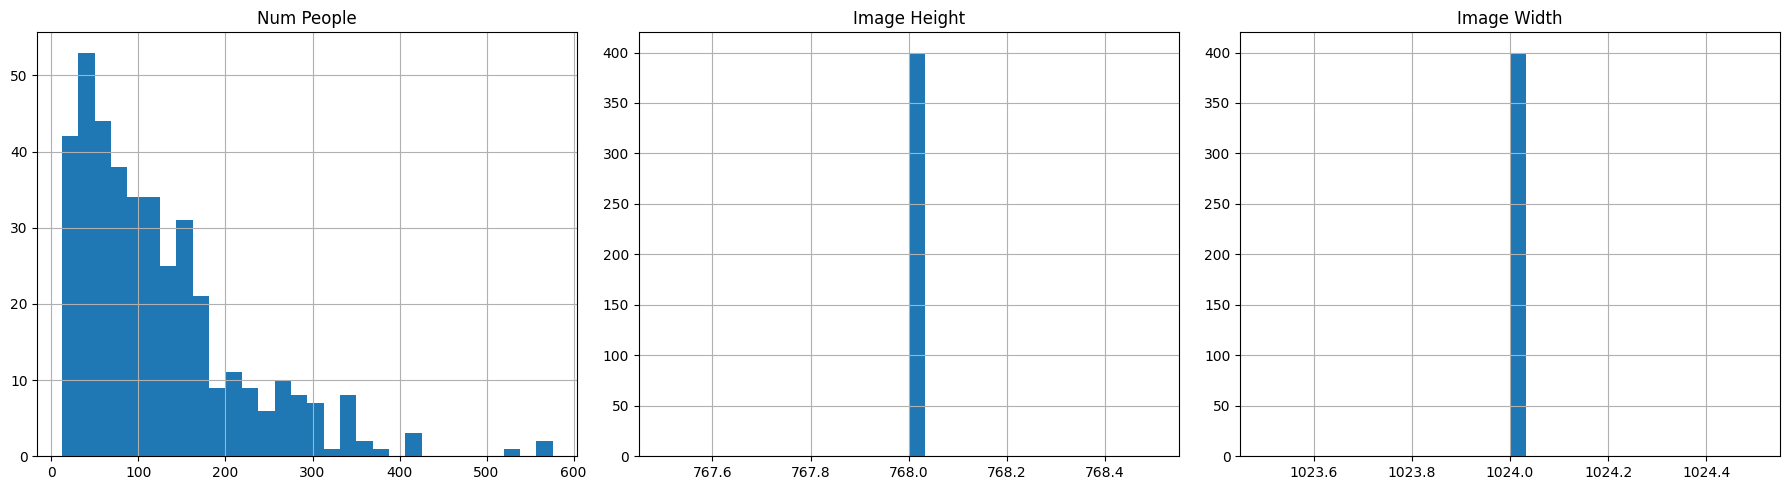

In [13]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
data["num_people"].hist(bins=30)
plt.title("Num People")

plt.subplot(1, 3, 2)
data["img_H"].hist(bins=30)
plt.title("Image Height")

plt.subplot(1, 3, 3)
data["img_W"].hist(bins=30)
plt.title("Image Width")

plt.tight_layout()
plt.show()


In [19]:
def sigma_from_nearest_neighbour(points, k=3, beta=0.3):
    """
    points: scaled points (H/8, W/8) , same resolution as density map
    k: nearest neighbour to calculate sigma
    beta: consonant
    """
    pts = np.asarray(points, dtype=np.float32)
    N = len(pts)
    if N == 0:
        return np.array([], dtype=np.float32)
    if N == 1:
        return np.array([1.0], dtype=np.float32) 

    # pairwise distances (N x N)
    diff = pts[:, None, :] - pts[None, :, :]
    dist = np.sqrt((diff ** 2).sum(axis=2))

    # ignore self-distance
    np.fill_diagonal(dist, np.inf)

    # k nearest distances for each point
    knn = np.sort(dist, axis=1)[:, :min(k, N-1)]
    d_i = knn.mean(axis=1)

    sigma = beta * d_i
    sigma = np.clip(sigma, 1e-6, None) 
    return sigma

def adaptive_gaussian_map(img, points):
    """
    return: downsampled density map 
    """
    H = img.shape[0] // 8
    W = img.shape[1] // 8

    points = points / 8.0
    density = np.zeros((H, W), dtype=np.float32)

    sigmas = sigma_from_nearest_neighbour(points)

    for i, (x0, y0) in enumerate(points):

        sigma = sigmas[i]
        sigma = max(sigma, 1.0)
        x0_int = int(round(x0))
        y0_int = int(round(y0))

        if not (0 <= x0_int < W and 0 <= y0_int < H):
            continue

        # Gaussian window size (3*sigma rule)
        radius = max(1, int(3 * sigma))
        x_min = max(0, x0_int - radius)
        x_max = min(W, x0_int + radius + 1)
        y_min = max(0, y0_int - radius)
        y_max = min(H, y0_int + radius + 1)

        xs = np.arange(x_min, x_max)
        ys = np.arange(y_min, y_max)
        xs, ys = np.meshgrid(xs, ys)

        # Gaussian centered at float (x0, y0)
        g = np.exp(-((xs - x0)**2 + (ys - y0)**2) / (2 * sigma**2))

        # normalize so each head contributes exactly 1
        s = g.sum()
        if s > 0:
            g /= s
        else:
            continue

        density[y_min:y_max, x_min:x_max] += g

    return density


In [20]:

def fixed_gaussian_map(points, img, sigma=4, truncate=3):
    H, W = img.shape[:2]
    dmap = np.zeros((H, W), dtype=np.float32)
    
    r = int(truncate * sigma)
    
    size = 2 * r + 1
    ax = np.arange(-r, r + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel_base = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

    for p in points:
        xi, yi = int(round(p[0])), int(round(p[1]))
        
        if xi < 0 or xi >= W or yi < 0 or yi >= H:
            continue

        x_min, x_max = max(0, xi - r), min(W, xi + r + 1)
        y_min, y_max = max(0, yi - r), min(H, yi + r + 1)

        kx_min = x_min - (xi - r)
        kx_max = kx_min + (x_max - x_min)
        ky_min = y_min - (yi - r)
        ky_max = ky_min + (y_max - y_min)

        patch = kernel_base[ky_min:ky_max, kx_min:kx_max]
        
        dmap[y_min:y_max, x_min:x_max] += patch / (patch.sum() + 1e-12)

    return dmap
def generate_low_res_dmap(img, points, stride=8, sigma=4):
    if torch.is_tensor(img):
        H, W = img.shape[1], img.shape[2]
    else:
        H, W = img.shape[0], img.shape[1]
    
    target_H, target_W = H // stride, W // stride
    
    low_res_canvas = np.zeros((target_H, target_W), dtype=np.float32)

    scaled_points = points / stride

    dmap = fixed_gaussian_map(scaled_points, low_res_canvas, sigma=sigma/stride)
    
    return dmap

In [15]:
class CrowdDataset(torch.utils.data.Dataset):
    def __init__(self, root_path, transform=None, fixed_sigma=False):
        self.root_path = Path(root_path)
        self.img_paths = sorted((self.root_path / "images").glob("*.jpg"))
        self.transform = transform
        self.fixed_sigma = fixed_sigma

        if not self.img_paths:
            raise FileNotFoundError(f"Gambar tidak ditemukan: {self.root_path / 'images'}")

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        gt_path = self.root_path / "ground-truth" / f"GT_{img_path.stem}.mat"

        data = loadmat(gt_path)
        points = np.asarray(data["image_info"][0, 0][0, 0][0], dtype=np.float32).reshape(-1, 2)
        real_people = len(points)

        img = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Gambar tidak terbaca: {img_path}")

        img_rgb_np = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.fixed_sigma:
            low_dmap_np = generate_low_res_dmap(img_rgb_np, points, sigma=4)
        else:
            low_dmap_np = adaptive_gaussian_map(img_rgb_np, points)

        if self.transform:
            img_t = self.transform(img_rgb_np)
        else:
            img_t = torch.from_numpy(img_rgb_np).permute(2, 0, 1).float() / 255.0

        dmap_t = torch.from_numpy(low_dmap_np).unsqueeze(0).float()
        people_t = torch.tensor(real_people, dtype=torch.float32)

        return img_t, dmap_t, people_t

In [17]:
transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(), 
    torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = CrowdDataset(TRAIN_PATH, transform=transform, fixed_sigma=False)

train_ratio = 0.8
n_total = len(dataset)
n_train = int(train_ratio * n_total)
n_val = n_total - n_train

train_set, val_set = torch.utils.data.random_split(
    dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

In [22]:
print("Jumlah train_set:", len(train_set))

n = min(n, len(train_set))
low_sums, people_counts = [], []

for i in range(n):
    _, dmap, people = train_set[i]
    low_sums.append(dmap.sum().item())
    people_counts.append(people.item())

Jumlah train_set: 320


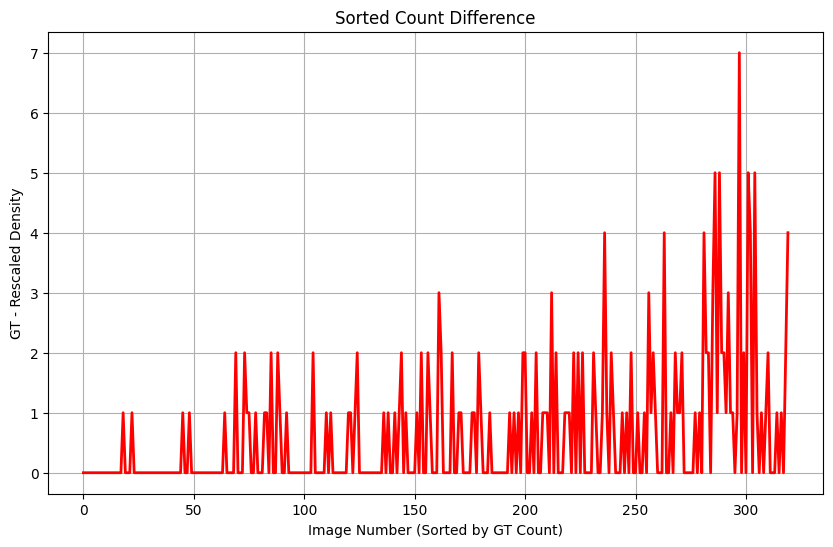

In [23]:
gt_counts = np.array(real_people)
rescaled_counts = np.array(low_sums)

difference_adapt = gt_counts - rescaled_counts

sorted_idx = np.argsort(gt_counts)

sorted_diff = difference_adapt[sorted_idx]

plt.figure(figsize=(10,6))
plt.plot(range(len(sorted_diff)), sorted_diff, color='red', linewidth=2)

plt.xlabel("Image Number (Sorted by GT Count)")
plt.ylabel("GT - Rescaled Density")
plt.title("Sorted Count Difference")
plt.grid(True)
plt.show()

In [24]:
difference_adapt.max()

np.float64(7.0)

In [26]:
print(np.mean(difference_adapt))
print(np.mean(difference_fixed))

0.5968746274709702
0.5968746274709702


In [27]:
print("Mean abs:", np.mean(np.abs(difference_fixed)))
print("Std:", np.std(difference_fixed))
print("Max abs:", np.max(np.abs(difference_fixed)))


Mean abs: 0.5968765825033188
Std: 1.050292589137134
Max abs: 7.0


In [28]:
print("Mean abs:", np.mean(np.abs(difference_adapt)))
print("Std:", np.std(difference_adapt))
print("Max abs:", np.max(np.abs(difference_adapt)))


Mean abs: 0.5968765825033188
Std: 1.050292589137134
Max abs: 7.0


## The Density Map is correctly sum up to the real count

In [29]:
from torch.utils.data import DataLoader
train_loader = DataLoader(
    train_set,
    batch_size=1, 
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

val_loader = DataLoader(
    val_set,
    batch_size=1,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

In [30]:
vgg = models.vgg16(pretrained=True)
class CSRNet(nn.Module):
     def __init__(self):
         super(CSRNet , self).__init__()
         self.frontend = nn.Sequential(
            *list(vgg.features.children())[:23]
         )
         backend_layers = []
         for _ in range(6):
            backend_layers += [
                nn.Conv2d(512, 512, 3, padding=2, dilation=2),
                nn.ReLU(inplace=True)
            ]
         self.backend = nn.Sequential(*backend_layers)
         self.output = nn.Conv2d(512, 1, kernel_size=1)
     def forward(self, x):
        x = self.frontend(x)
        x = self.backend(x)
        x = self.output(x)
        return x

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 262MB/s] 


In [31]:
model = CSRNet()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-6)
criterion = torch.nn.MSELoss()

In [36]:
def train_loop(epochs, train_loader, val_loader, loss_fn, optimizer, model, device):
    model.to(device)

    mae_people_val_history = []
    mae_people_train_history = []
    loss_val_history = []
    loss_train_history = []
    mae_people_val_real = []
    best_val_people_mae = float("inf")

    for epoch in tqdm(range(epochs)):
        t0 = time.time()
        total_loss = 0.0
        total_people_mae_down = 0.0
        model.train()
        for batch_idx, (img,  dmap, real_people) in enumerate(train_loader):
            img = img.to(device)
            num_people = dmap.sum(dim=(1,2,3))
            real_people = real_people.to(device)

            optimizer.zero_grad()
            pred = model(img)
            loss = loss_fn(pred, dmap)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() 

            people_pred = pred.sum(dim=(1, 2, 3))
            total_people_mae_down += torch.abs(people_pred - num_people).sum().item()
            if batch_idx % 20 == 0:
                print(f"Batch: {batch_idx + 1}/{len(train_loader)} Loss: {loss.item():.6f}")

        mae_people_train = total_people_mae_down / len(train_loader.dataset) 
        mae_people_val, loss_val, mae_real = eval_loop(val_loader, loss_fn, model, device)
        train_loss = total_loss / len(train_loader)

        mae_people_train_history.append(mae_people_train)
        loss_train_history.append(train_loss)
        mae_people_val_history.append(mae_people_val)
        mae_people_val_real.append(mae_real)
        loss_val_history.append(loss_val)
        # save last
        torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "last_mae": mae_people_val,
                "mae_real": mae_real
            }, 
        "last_csrnet.pth")

        # save best
        if mae_people_val < best_val_people_mae:
            best_val_people_mae = mae_people_val
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "best_mae": best_val_people_mae,
                "mae_real" : mae_real
            }, "best_csrnet.pth"
            )

        print(
          f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.6f} | "
          f"Train MAE: {mae_people_train:.2f} | "
          f"Val Loss: {loss_val:.6f} | "
          f"Val Mae Real: {mae_real:.2f}"
          f"Val MAE: {mae_people_val:.2f} | "
          f"Time: {time.time() - t0:.2f}s"
        )

    return {
        "train_loss": loss_train_history,
        "train_mae": mae_people_train_history,
        "val_loss": loss_val_history,
        "val_mae": mae_people_val_history,
        "best_val_mae": best_val_people_mae,
    }


def eval_loop(val_loader, loss_fn, model, device):
    model.eval()
    total_people_error = 0.0
    total_loss = 0.0
    total_people_error_real = 0.0
    with torch.no_grad():
        for img, dmap_down, real_people in val_loader:
            img = img.to(device)
            dmap_down = dmap_down.to(device)
            real_people = real_people.to(device).float()

            num_people = dmap_down.sum(dim=(1,2,3))

            dmap_pred = model(img)


            total_loss += loss_fn(dmap_pred, dmap_down).item()

            people_pred = dmap_pred.sum(dim=(1,2,3))
            total_people_error += torch.abs(people_pred - num_people).sum().item()
            total_people_error_real += torch.abs(people_pred - real_people).sum().item()


    mae_people = total_people_error / len(val_loader.dataset)
    mae_people_real = total_people_error_real / len(val_loader.dataset)
    avg_loss = total_loss / len(val_loader)
    return mae_people, avg_loss, mae_people_real
def run_epoch(loader, training=False):
    model.train(training)
    total_loss, absolute_error, squared_error, total_samples = 0.0, 0.0, 0.0, 0
    predictions = []

    with torch.set_grad_enabled(training):
        for images, density, people in tqdm(loader, desc="Train" if training else "Evaluate", leave=False):
            images = images.to(device, non_blocking=True)
            density = density.to(device, non_blocking=True)
            people = people.to(device, non_blocking=True).float().reshape(-1)

            if training:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            if outputs.shape != density.shape:
                raise ValueError(f"Output {outputs.shape} berbeda dengan target {density.shape}")
            loss = criterion(outputs, density)

            if not torch.isfinite(loss):
                raise FloatingPointError("Loss NaN atau Inf.")

            if training:
                loss.backward()
                optimizer.step()

            counts = outputs.detach().sum(dim=(1, 2, 3))
            errors = counts - people
            batch_size = images.size(0)

            total_loss += loss.item() * batch_size
            absolute_error += errors.abs().sum().item()
            squared_error += errors.square().sum().item()
            total_samples += batch_size

            predictions.extend(zip(people.detach().cpu().tolist(), counts.cpu().tolist()))

    if total_samples == 0:
        raise ValueError("Dataset kosong.")

    metrics = {
        "loss": total_loss / total_samples,
        "mae": absolute_error / total_samples,
        "rmse": (squared_error / total_samples) ** 0.5,
    }

    return metrics, predictions


In [37]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

test_set = CrowdDataset(TEST_PATH, transform=transform, fixed_sigma=dataset.fixed_sigma)
test_loader = DataLoader(test_set, batch_size=1, shuffle=False, num_workers=0, pin_memory=device.type == "cuda")

epochs = 40
best_val_mae = float("inf")
history = []

for epoch in range(1, epochs + 1):
    started = time.time()
    train_metrics, _ = run_epoch(train_loader, training=True)
    val_metrics, _ = run_epoch(val_loader)

    improved = val_metrics["mae"] < best_val_mae
    best_val_mae = min(best_val_mae, val_metrics["mae"])

    checkpoint = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "best_val_mae": best_val_mae,
    }

    torch.save(checkpoint, "last_csrnet.pth")

    if improved:
        torch.save(checkpoint, "best_csrnet.pth")

    history.append({
        "epoch": epoch,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{f"val_{key}": value for key, value in val_metrics.items()},
    })

    pd.DataFrame(history).to_csv("training_history.csv", index=False)

    print(
        f"Epoch {epoch:03d}/{epochs} | "
        f"Train Loss {train_metrics['loss']:.6f} | Train MAE {train_metrics['mae']:.2f} | "
        f"Val Loss {val_metrics['loss']:.6f} | Val MAE {val_metrics['mae']:.2f} | "
        f"Val RMSE {val_metrics['rmse']:.2f} | Time {time.time() - started:.1f}s"
    )

Train:   0%|          | 0/320 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 001/40 | Train Loss 0.001320 | Train MAE 51.45 | Val Loss 0.001045 | Val MAE 71.31 | Val RMSE 76.41 | Time 189.9s


Train:   0%|          | 0/320 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a5eadb458a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a5eadb458a0>

Traceback (most recent call last):
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7a5eadb458a0>self._shutdown_workers()


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():        if w

...

Epoch 039/40 | Train Loss 0.000239 | Train MAE 10.62 | Val Loss 0.000484 | Val MAE 10.40 | Val RMSE 15.13 | Time 191.9s


Train:   0%|          | 0/320 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a5eadb458a0>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a5eadb458a0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
self._shutdown_workers()  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError:     can only test a child processif w.is_alive():

  File "/usr/lib/

Evaluate:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 040/40 | Train Loss 0.000283 | Train MAE 16.64 | Val Loss 0.000507 | Val MAE 28.08 | Val RMSE 30.30 | Time 192.2s


# Inference on test & valid

In [38]:
checkpoint = torch.load("best_csrnet.pth", map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state"])


def get_filename(ds, idx):
    while isinstance(ds, torch.utils.data.Subset):
        idx = ds.indices[idx]
        ds = ds.dataset
    return Path(ds.img_paths[idx]).name


valid_inference_loader = DataLoader(val_set, batch_size=1, shuffle=False, num_workers=0)

for name, loader in [("valid", valid_inference_loader), ("test", test_loader)]:
    metrics, predictions = run_epoch(loader)
    results = pd.DataFrame(predictions, columns=["real_count", "pred_count"])
    results.insert(0, "filename", [get_filename(loader.dataset, i) for i in range(len(results))])
    results["absolute_error"] = (results["pred_count"] - results["real_count"]).abs()
    results.to_csv(f"{name}_predictions.csv", index=False)

    print(f"{name.upper()} | Best Epoch {checkpoint['epoch']} | MAE {metrics['mae']:.2f} | RMSE {metrics['rmse']:.2f}")

Evaluate:   0%|          | 0/80 [00:00<?, ?it/s]

VALID | Best Epoch 38 | MAE 9.66 | RMSE 14.57


Evaluate:   0%|          | 0/316 [00:00<?, ?it/s]

TEST | Best Epoch 38 | MAE 11.07 | RMSE 16.92


# Training Evaluation

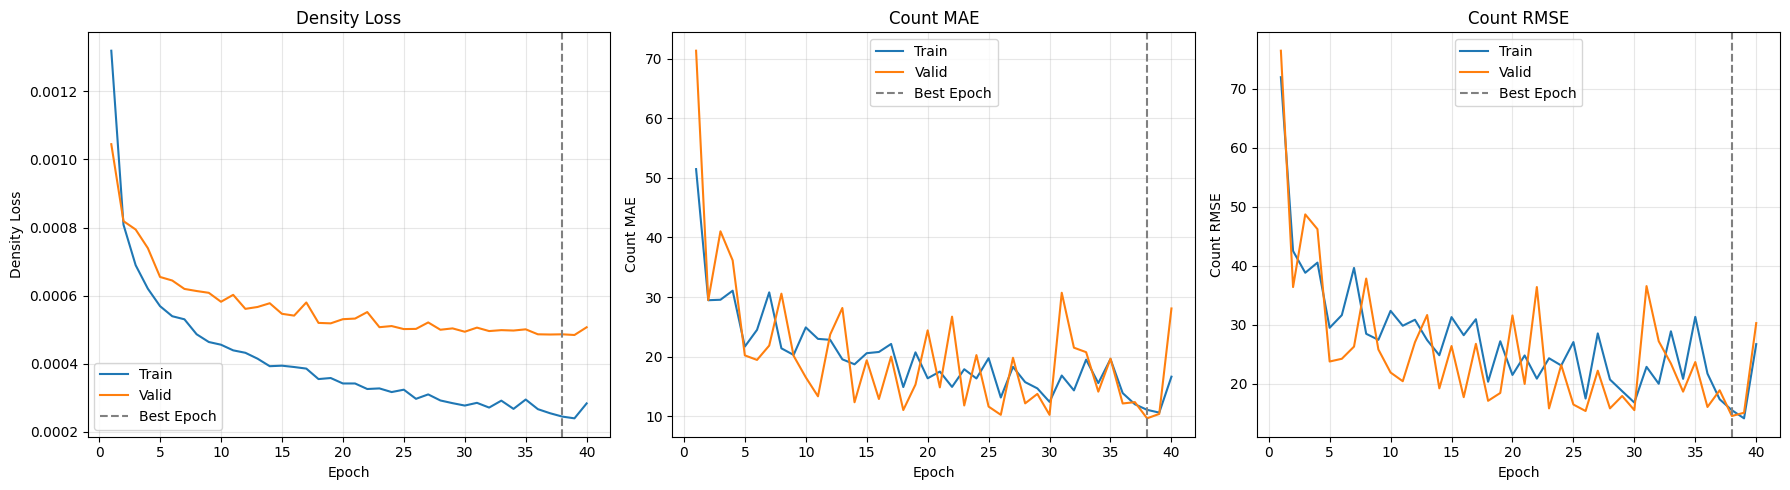

In [40]:
history_df = pd.read_csv("training_history.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(axes, ["loss", "mae", "rmse"], ["Density Loss", "Count MAE", "Count RMSE"]):
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], label="Train")
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Valid")
    ax.axvline(checkpoint["epoch"], color="gray", linestyle="--", label="Best Epoch")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()